# RoadScan — data and error diagnosis
Investigate annotation structure, country/class support and detector errors before spending more GPU time. All inference in this notebook runs on CPU. Only the saved training and development manifests are opened. Previously exposed test sets remain excluded. Numeric checks cannot certify semantic annotation correctness; the rendered contact sheets require visual review.


## 1. Environment and fixed inputs
Pin the same detection library, reuse Kaggle PyTorch, and limit CPU inference threads. Load notebook 06 manifests directly so the established split and duplicate exclusions are preserved.


In [1]:
import sys, subprocess, json, shutil, hashlib, time
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--retries', '2', '--timeout', '30', 'ultralytics==8.4.177'], check=True, timeout=180)
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou
torch.set_num_threads(2)
SEED=42
CLASSES=['D00','D10','D20','D40']
OUT=Path('/kaggle/working/diagnosis')
OUT.mkdir(exist_ok=True)
BASE=Path('/kaggle/input/notebooks/rimasabunasser/06-roadscan-quality-improvement/roadscan_v2')
SOURCE=Path('/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo')
assert (BASE/'train_manifest.csv').is_file(), 'Attach notebook 06 output.'
assert (SOURCE/'train/images').is_dir(), 'Attach roadscan-yolo.'
def rebase(p):return str(SOURCE/str(p).split('/RoadScan_yolo/',1)[1])
tables={}
for split in ['train','in_domain_dev','china_dev']:
    t=pd.read_csv(BASE/f'{split}_manifest.csv')
    t['path']=t.path.map(rebase);t['label']=t.label.map(rebase)
    t['country']=t.path.map(lambda p:Path(p).stem.split('_')[0])
    tables[split]=t
assert [len(tables[s]) for s in tables]==[11149,1000,1977]
assert set(tables['train'].path).isdisjoint(set(tables['in_domain_dev'].path)|set(tables['china_dev'].path))
checkpoint=BASE/'runs/yolo26s_768/weights/best.pt'
assert checkpoint.is_file()
model=YOLO(str(checkpoint))
assert list(model.names.values())==CLASSES
print('CPU diagnosis ready. Fixed split counts:', {k:len(v) for k,v in tables.items()}, flush=True)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CPU diagnosis ready. Fixed split counts: {'train': 11149, 'in_domain_dev': 1000, 'china_dev': 1977}


## 2. Audit every training/development label
Check missing files, five-column YOLO format, finite coordinates, valid class IDs, positive dimensions, normalized centres and box edges. Report duplicates rather than silently deleting them. Summaries count both images containing a class and individual boxes. No labels or split membership are changed.


In [2]:
def read_labels(path):
    lines=Path(path).read_text().splitlines()
    return np.asarray([list(map(float,l.split())) for l in lines if l.strip()], dtype=float).reshape(-1,5)
def audit(item):
    split,row=item
    issue=[];boxes=[]
    p=Path(row.label)
    if not Path(row.path).is_file():issue.append('missing_image')
    if not p.is_file():return dict(split=split,path=row.path,issues='missing_label',empty=False,boxes=0,**{c:0 for c in CLASSES}),[]
    try:
        a=read_labels(p)
        if not np.isfinite(a).all():issue.append('nonfinite')
        if len(a):
            if not ((a[:,0]==a[:,0].astype(int))&(a[:,0]>=0)&(a[:,0]<4)).all():issue.append('class_id')
            if not ((a[:,1:3]>=0)&(a[:,1:3]<=1)).all():issue.append('centre_range')
            if not ((a[:,3:]>0)&(a[:,3:]<=1)).all():issue.append('box_size')
            if ((a[:,1:3]-a[:,3:]/2 < -2e-6)|(a[:,1:3]+a[:,3:]/2 > 1+2e-6)).any():issue.append('box_outside')
            if len(np.unique(a,axis=0))<len(a):issue.append('duplicate_box')
        for c,x,y,w,h in a:boxes.append(dict(split=split,country=row.country,path=row.path,class_name=CLASSES[int(c)] if c in range(4) else 'invalid',width=w,height=h,area=w*h))
        counts={c:int((a[:,0]==i).sum()) for i,c in enumerate(CLASSES)}
        return dict(split=split,country=row.country,path=row.path,label=row.label,issues=';'.join(issue),empty=len(a)==0,boxes=len(a),**counts),boxes
    except Exception as e:
        return dict(split=split,country=row.country,path=row.path,label=row.label,issues=type(e).__name__+':'+str(e),empty=False,boxes=0,**{c:0 for c in CLASSES}),[]
items=[(s,r) for s,t in tables.items() for r in t.itertuples()]
with ThreadPoolExecutor(max_workers=8) as pool:audited=list(pool.map(audit,items))
audit_rows=pd.DataFrame([a for a,b in audited]);box_rows=pd.DataFrame([r for a,b in audited for r in b])
audit_rows.to_csv(OUT/'label_audit.csv',index=False);box_rows.to_csv(OUT/'box_geometry.csv',index=False)
issues=audit_rows[audit_rows.issues!='']
summary=audit_rows.groupby(['split','country']).agg(images=('path','size'),backgrounds=('empty','sum'),boxes=('boxes','sum'))
summary['background_fraction']=summary.backgrounds/summary.images
summary.to_csv(OUT/'country_support.csv')
display(summary);display(issues.head(30));print('Images with numeric/file warnings:',len(issues),flush=True)
class_summary=[]
for (split,country),g in audit_rows.groupby(['split','country']):
    for c in CLASSES:class_summary.append(dict(split=split,country=country,class_name=c,images=int((g[c]>0).sum()),boxes=int(g[c].sum())))
class_summary=pd.DataFrame(class_summary);class_summary.to_csv(OUT/'class_support.csv',index=False);display(class_summary)
display(box_rows.groupby(['split','class_name'])[['width','height','area']].median())


images  backgrounds  boxes  background_fraction
split         country                                                 
china_dev     China      1977           43   4650             0.021750
in_domain_dev Czech       202          133    110             0.658416
              India       124           67    108             0.540323
              Japan       674          158   1042             0.234421
train         Czech      1271          788    783             0.619984
              India      4471         2617   3916             0.585328
              Japan      5407         1361   8531             0.251711

,split,country,path,label,issues,empty,boxes,D00,D10,D20,D40


Images with numeric/file warnings: 0


,split,country,class_name,images,boxes
0,china_dev,China,D00,1419,2678
1,china_dev,China,D10,738,1096
2,china_dev,China,D20,486,641
3,china_dev,China,D40,164,235
4,in_domain_dev,Czech,D00,50,62
5,in_domain_dev,Czech,D10,13,17
6,in_domain_dev,Czech,D20,10,14
7,in_domain_dev,Czech,D40,13,17
8,in_domain_dev,India,D00,15,17
9,in_domain_dev,India,D10,1,1


width    height      area
split         class_name                              
china_dev     D00         0.117188  0.332031  0.044105
              D10         0.416016  0.067383  0.026876
              D20         0.474609  0.345703  0.171917
              D40         0.041016  0.048828  0.002136
in_domain_dev D00         0.100000  0.140000  0.013292
              D10         0.228149  0.045000  0.009994
              D20         0.340000  0.255556  0.094792
              D40         0.091667  0.055000  0.004908
train         D00         0.101389  0.144444  0.014625
              D10         0.211667  0.041667  0.009244
              D20         0.346667  0.243333  0.088436
              D40         0.104167  0.060000  0.006261

## 3. Define a reproducible diagnostic sample
Select 60 examples per country: 40 class-targeted draws (10 per class, de-duplicated) followed by random fill. Include up to 10 background images when available. This deliberately class-aware sample diagnoses failures; its precision/recall is not an unbiased population estimate. Keep the full validation scores from notebook 08 as the performance reference.


In [3]:
parts=[]
for (split,country),g in audit_rows[audit_rows.issues==''].groupby(['split','country']):
    picks=[]
    for c in CLASSES:
        pool=g[g[c]>0];picks.extend(pool.sample(n=min(10,len(pool)),random_state=SEED).index)
    empty=g[g['empty']]
    picks.extend(empty.sample(n=min(10,len(empty)),random_state=SEED).index)
    picks=list(dict.fromkeys(picks));left=g.drop(index=picks)
    picks.extend(left.sample(n=min(60-len(picks),len(left)),random_state=SEED).index)
    parts.append(g.loc[picks])
sample=pd.concat(parts).reset_index(drop=True)
sample.to_csv(OUT/'diagnostic_sample.csv',index=False)
print('Diagnostic sample:',sample.groupby(['split','country']).size().to_dict(),flush=True)


Diagnostic sample: {('china_dev', 'China'): 60, ('in_domain_dev', 'Czech'): 60, ('in_domain_dev', 'India'): 60, ('in_domain_dev', 'Japan'): 60, ('train', 'Czech'): 60, ('train', 'India'): 60, ('train', 'Japan'): 60}


## 4. Match CPU predictions to ground truth
Run at a fixed confidence of 0.25 and IoU matching threshold of 0.50. Greedily match same-class boxes in descending prediction confidence. Unmatched predictions are false positives; unmatched annotations are false negatives. A separate overlap flag distinguishes likely class confusion from localization, duplicate predictions and background-like false positives. These are diagnostic flags, not definitive human labels.


In [5]:
def truth_xyxy(a,w,h):
    if not len(a):return np.empty((0,4))
    out=a[:,1:].copy();out[:,0]=(a[:,1]-a[:,3]/2)*w;out[:,1]=(a[:,2]-a[:,4]/2)*h
    out[:,2]=(a[:,1]+a[:,3]/2)*w;out[:,3]=(a[:,2]+a[:,4]/2)*h
    return out
error_rows=[];class_errors=[];examples=[]
started=time.monotonic()
for k,row in enumerate(sample.itertuples()):
    result=model.predict(row.path,imgsz=640,conf=0.25,iou=0.7,max_det=300,nms=True,rect=False,device='cpu',verbose=False)[0]
    h,w=result.orig_shape;gt=read_labels(row.label);gb=truth_xyxy(gt,w,h)
    pb=result.boxes.xyxy.cpu().numpy();pc=result.boxes.cls.cpu().numpy().astype(int);scores=result.boxes.conf.cpu().numpy()
    overlap=box_iou(torch.tensor(pb),torch.tensor(gb)).numpy() if len(pb) and len(gb) else np.zeros((len(pb),len(gb)))
    used=set();matched=[];fp_types=[]
    for j in np.argsort(-scores):
        eligible=[i for i in range(len(gt)) if i not in used and int(gt[i,0])==pc[j] and overlap[j,i]>=0.5]
        if eligible:
            i=max(eligible,key=lambda i:overlap[j,i]);used.add(i);matched.append((j,i));continue
        if len(gt) and overlap[j].max()>=0.5:
            best=int(overlap[j].argmax());kind='class_confusion' if pc[j]!=int(gt[best,0]) else 'duplicate'
        elif len(gt) and overlap[j].max()>=0.1:kind='localization'
        else:kind='background_like'
        fp_types.append((int(j),kind))
    tp=len(matched);fp=len(pb)-tp;fn=len(gt)-tp
    error_rows.append(dict(split=row.split,country=row.country,path=row.path,tp=tp,fp=fp,fn=fn,gt=len(gt),pred=len(pb),**dict(Counter(t for j,t in fp_types))))
    for c in range(4):class_errors.append(dict(split=row.split,country=row.country,class_name=CLASSES[c],tp=sum(pc[j]==c for j,i in matched),fp=sum(pc[j]==c for j,t in fp_types),fn=sum(int(gt[i,0])==c for i in range(len(gt)) if i not in used)))
    examples.append(dict(path=row.path,split=row.split,country=row.country,gt=gt.tolist(),pred_boxes=pb.tolist(),pred_class=pc.tolist(),confidence=scores.tolist(),tp=tp,fp=fp,fn=fn,fp_types=fp_types))
    if (k+1)%30==0:print('CPU predictions:',k+1,'/',len(sample),flush=True)
errors=pd.DataFrame(error_rows).fillna(0);ce=pd.DataFrame(class_errors)
errors.to_csv(OUT/'image_errors.csv',index=False);ce.to_csv(OUT/'sample_class_errors.csv',index=False)
(OUT/'predictions.json').write_text(json.dumps(examples))
display(errors.groupby(['split','country'])[['tp','fp','fn','gt','pred']].sum())
display(ce.groupby(['split','class_name'])[['tp','fp','fn']].sum())
print('CPU diagnostic inference seconds:',round(time.monotonic()-started,1),flush=True)


CPU predictions: 30 / 420
CPU predictions: 60 / 420
CPU predictions: 90 / 420
CPU predictions: 120 / 420
CPU predictions: 150 / 420
CPU predictions: 180 / 420
CPU predictions: 210 / 420
CPU predictions: 240 / 420
CPU predictions: 270 / 420
CPU predictions: 300 / 420
CPU predictions: 330 / 420
CPU predictions: 360 / 420
CPU predictions: 390 / 420
CPU predictions: 420 / 420


tp  fp  fn   gt  pred
split         country                       
china_dev     China    37  35  94  131    72
in_domain_dev Czech    19  20  50   69    39
              India    34  17  39   73    51
              Japan    48  33  56  104    81
train         Czech    53  18  47  100    71
              India    59  15  58  117    74
              Japan    75  23  38  113    98

tp  fp  fn
split         class_name            
china_dev     D00          9  11  49
              D10         19  15  18
              D20          8   6  14
              D40          1   3  13
in_domain_dev D00         23  17  40
              D10         13  15  29
              D20         42  22  25
              D40         23  16  51
train         D00         46  14  44
              D10         32   8  38
              D20         55  18  25
              D40         54  16  36

CPU diagnostic inference seconds: 99.4


## 5. Inspect annotated images beside predictions
Green boxes show the supplied labels; orange boxes show predictions. Inspect original image content, damage extent, shadows, road markings and possible missing annotations. Show both random controls and the largest observed errors. These selected images explain failure modes and must not be presented as a representative performance score.


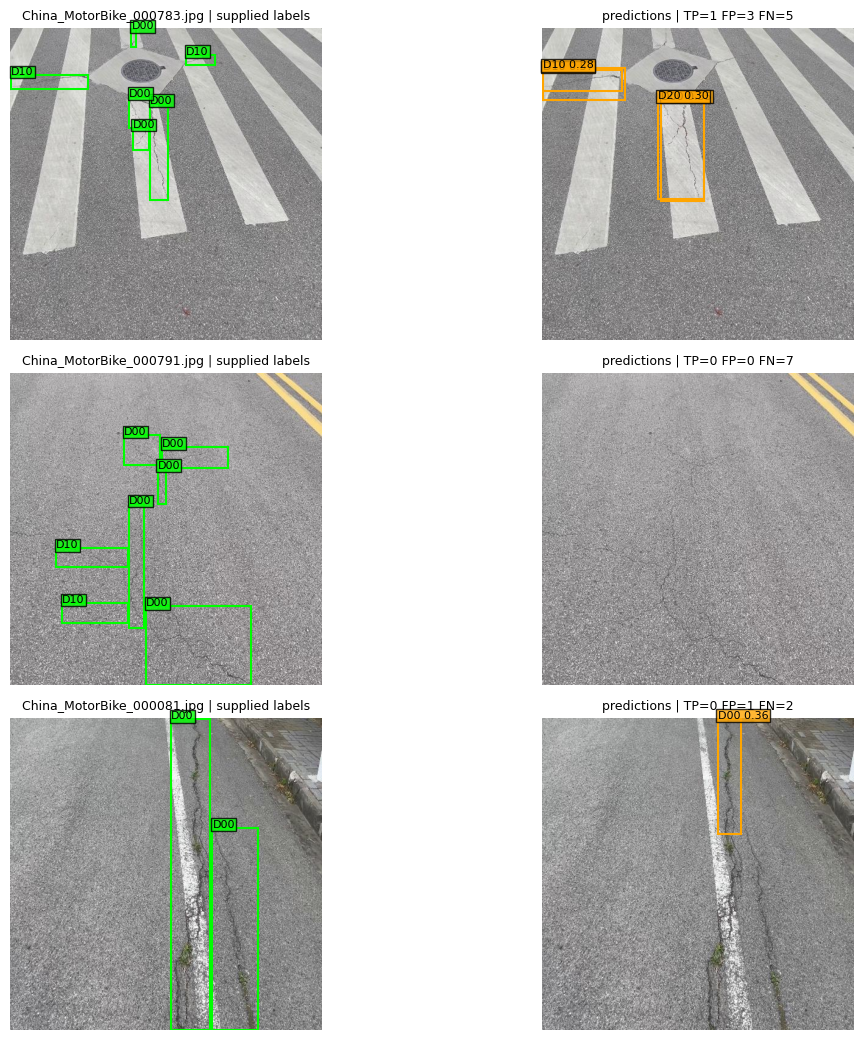

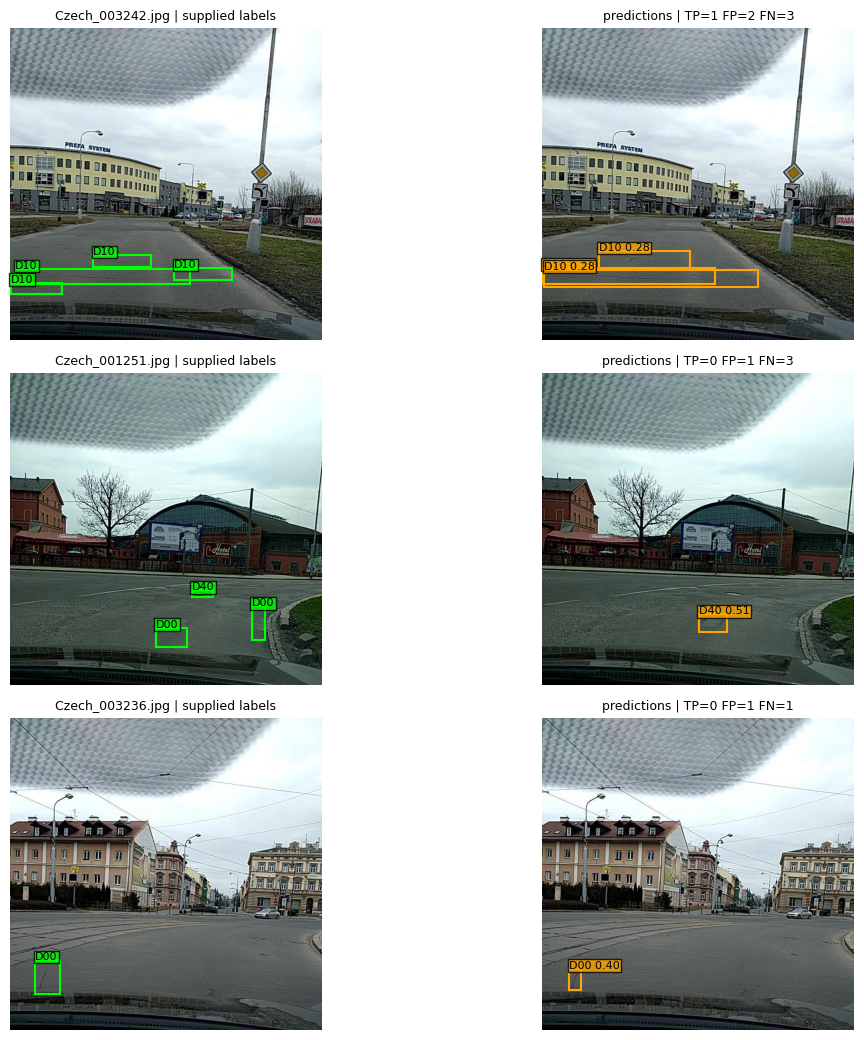

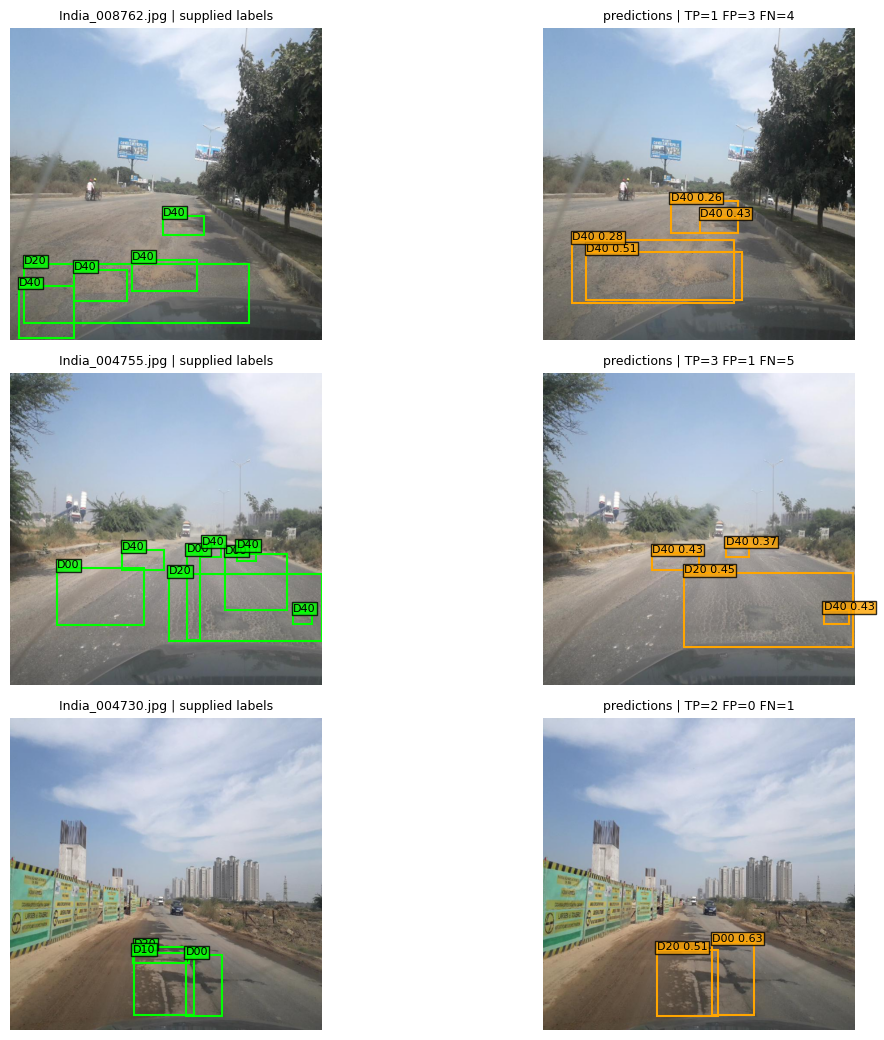

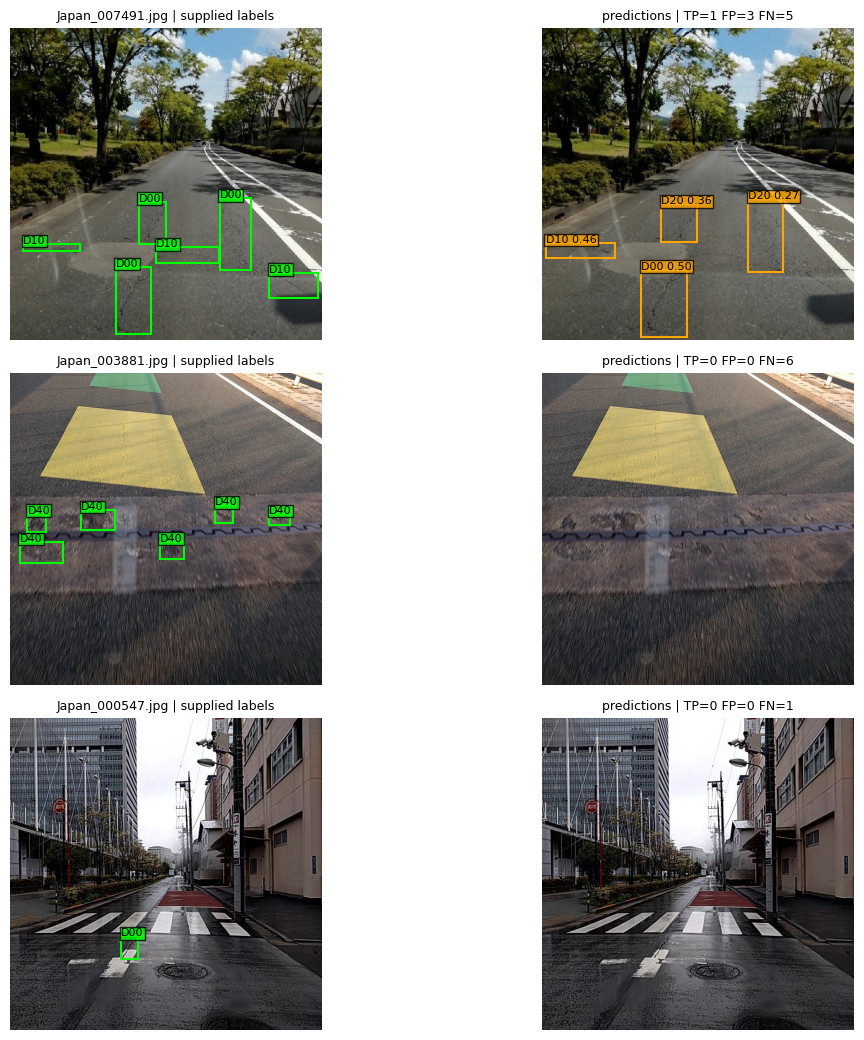

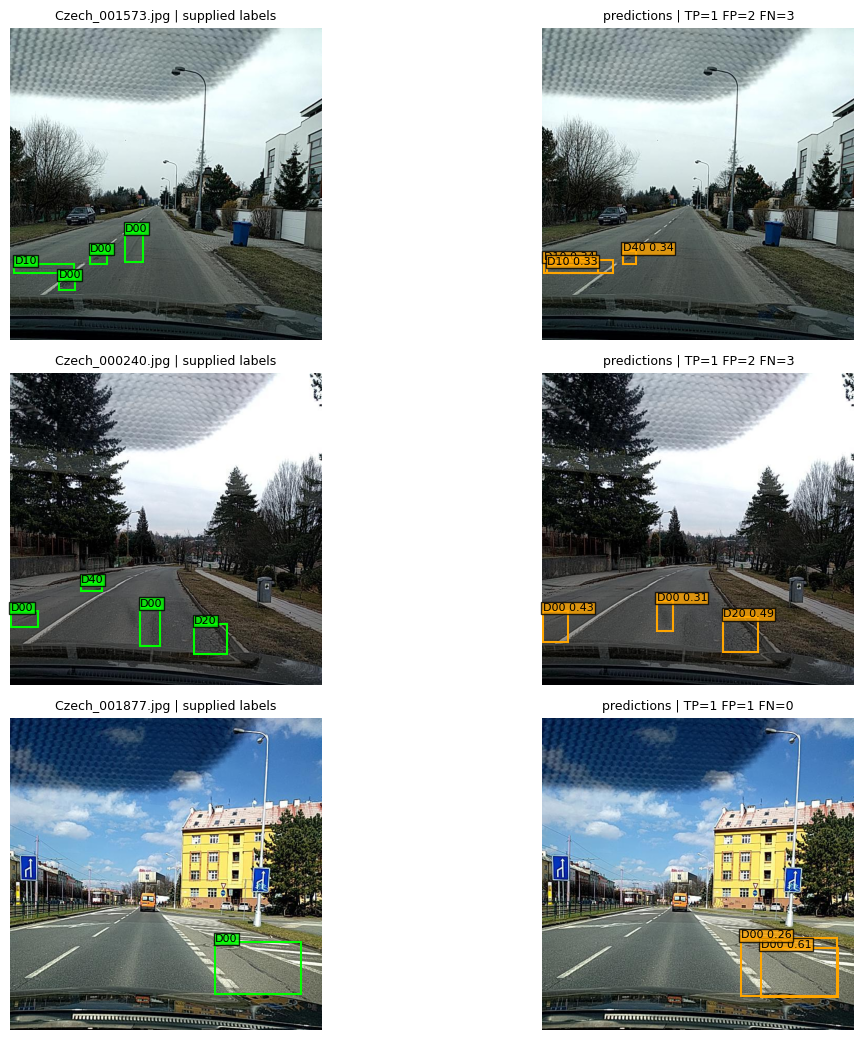

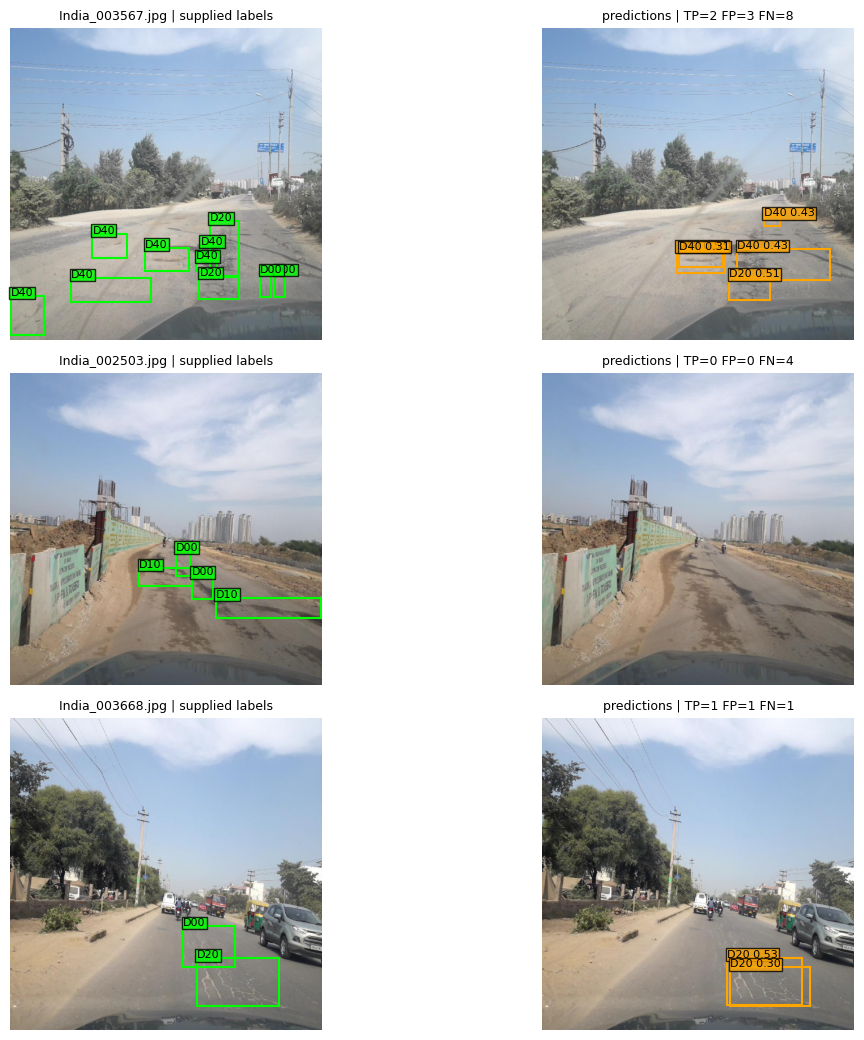

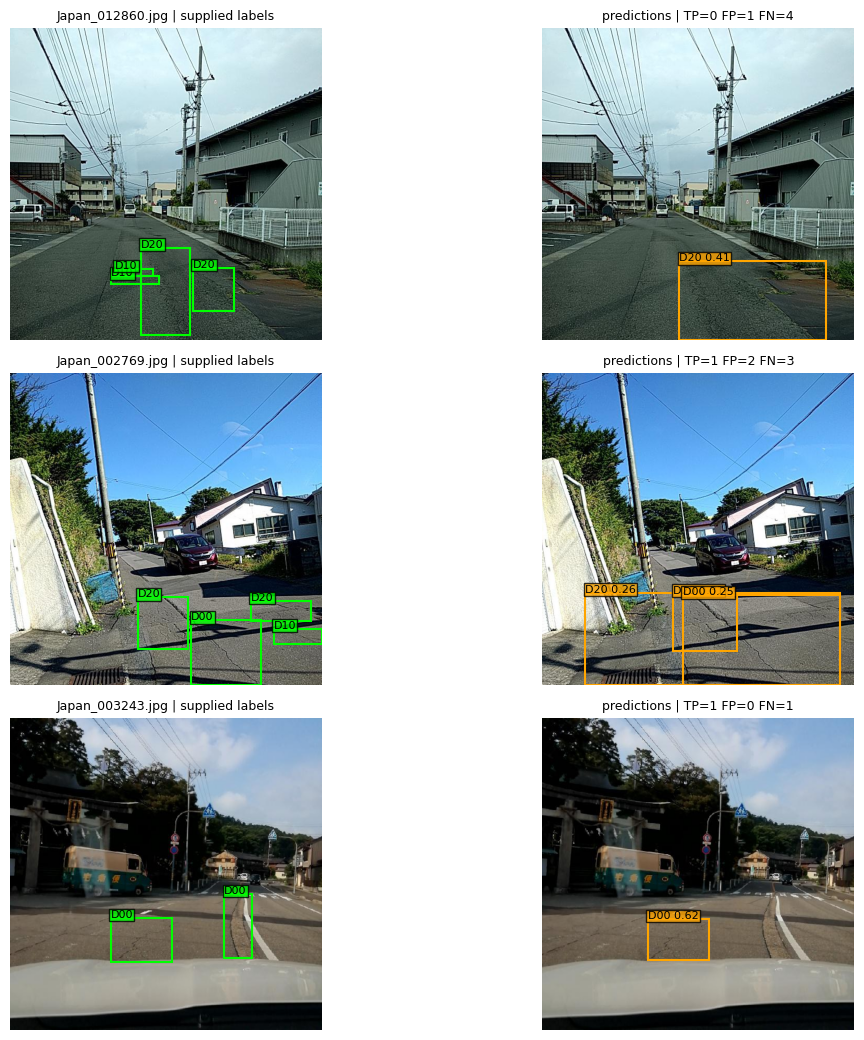

In [7]:
by_path={e['path']:e for e in examples}
def render_sheet(selected,name):
    fig,axes=plt.subplots(len(selected),2,figsize=(13,3.5*len(selected)),squeeze=False)
    for row_index,e in enumerate(selected):
        image=Image.open(e['path']).convert('RGB');w,h=image.size
        gt=np.asarray(e['gt']).reshape(-1,5);boxes=truth_xyxy(gt,w,h)
        for col in range(2):axes[row_index,col].imshow(image);axes[row_index,col].axis('off')
        for b,c in zip(boxes,gt[:,0]):
            x1,y1,x2,y2=b;axes[row_index,0].add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='lime',linewidth=1.5));axes[row_index,0].text(x1,y1,CLASSES[int(c)],color='black',fontsize=8,bbox=dict(facecolor='lime',alpha=.8,pad=1))
        for b,c,s in zip(e['pred_boxes'],e['pred_class'],e['confidence']):
            x1,y1,x2,y2=b;axes[row_index,1].add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='orange',linewidth=1.5));axes[row_index,1].text(x1,y1,f'{CLASSES[c]} {s:.2f}',fontsize=8,color='black',bbox=dict(facecolor='orange',alpha=.8,pad=1))
        axes[row_index,0].set_title(Path(e['path']).name+' | supplied labels',fontsize=9)
        axes[row_index,1].set_title(f"predictions | TP={e['tp']} FP={e['fp']} FN={e['fn']}",fontsize=9)
    fig.tight_layout();fig.savefig(OUT/(name+'.jpg'),dpi=110);plt.show();plt.close(fig)
for (split,country),group in errors.groupby(['split','country']):
    group=group.copy();group['mistakes']=group.fp+group.fn
    worst=group.sort_values('mistakes',ascending=False).head(2).path.tolist()
    control=group[~group.path.isin(worst)].sample(n=1,random_state=SEED).path.tolist()
    render_sheet([by_path[p] for p in worst+control],split+'_'+country+'_review')


## 6. Prepare a bounded, fair freezing comparison
Create one fixed 2,400-image training subset (800 from each training country) without moving any development/test image into training. Preserve natural class/background variation by random sampling; no label corrections or resampling are applied yet. Prepare a 400-image monitor, 200 per development domain. Compare head-only, last three top-level modules, and all-layer fine-tuning from the same saved road-damage checkpoint. This tests short additional adaptation, not training from scratch and not the best possible long-run model. Report the actual module indices because “last three layers” is architecture dependent.


In [8]:
trial=OUT/'freeze_inputs';trial.mkdir(exist_ok=True)
train=tables['train'].groupby('country',group_keys=False).sample(n=800,random_state=SEED).sort_values('path').reset_index(drop=True)
monitor=pd.concat([tables[s].sample(n=200,random_state=SEED).assign(domain=s) for s in ['in_domain_dev','china_dev']]).reset_index(drop=True)
train.to_csv(trial/'pilot_train_manifest.csv',index=False);monitor.to_csv(trial/'pilot_monitor_manifest.csv',index=False)
for s in ['in_domain_dev','china_dev']:tables[s].to_csv(trial/(s+'_manifest.csv'),index=False)
shutil.copy2(checkpoint,trial/'start.pt')
modules=model.model.model
architecture=pd.DataFrame([dict(index=i,module=type(m).__name__,parameters=sum(p.numel() for p in m.parameters())) for i,m in enumerate(modules)])
architecture.to_csv(trial/'architecture.csv',index=False);display(architecture)
assert type(modules[-1]).__name__=='Detect'
plan=dict(seed=SEED,imgsz=640,batch=16,epochs=4,optimizer='AdamW',lr0=0.0001,weight_decay=0.0005,mosaic=0.0,train_images=2400,monitor_images=400,
    arms={'head_only':len(modules)-1,'last_three_modules':len(modules)-3,'all_layers':None},
    start_sha256=hashlib.sha256((trial/'start.pt').read_bytes()).hexdigest(),
    policy='Same starting weights, images, optimizer, augmentations and epoch count. Rank by worst full-development domain AP50-95. Never test. A pilot cannot establish universal generalization.',
    max_gpu_minutes=30)
(trial/'plan.json').write_text(json.dumps(plan,indent=2))
issues.to_csv(OUT/'issues.csv',index=False)
report=['# RoadScan data diagnosis',f'Images checked: {len(audit_rows)}',f'Numeric/file warnings: {len(issues)}','## Country support',summary.to_markdown(),'## Diagnostic error counts (class-aware sample, not a population estimate)',errors.groupby(['split','country'])[['tp','fp','fn','gt','pred']].sum().to_markdown(),'## Diagnostic class errors',ce.groupby(['split','class_name'])[['tp','fp','fn']].sum().to_markdown(),'## Limits','No test annotations were opened. Numeric checks do not prove semantic label quality. Human visual inspection is required. Frozen-layer comparison is a short pilot; no 92% claim is made.']
(OUT/'REPORT.md').write_text('\n\n'.join(report))
print('CPU diagnosis completed. Prepared pilot:',json.dumps(plan,indent=2),flush=True)

review_notes = "# Visual review of diagnostic contact sheets\n\nReviewed selected examples from China and the training/development countries. This is a limited visual review, not annotation certification.\n\n- Supplied boxes generally lie on visible road damage in the inspected images; no obvious dataset-wide coordinate shift was observed.\n- Selected China images show close, near-downward road views, whereas inspected Czech, India and Japan examples show forward vehicle views. This supports a viewpoint/domain-shift hypothesis.\n- Several predictions merge adjacent labeled regions or cover only part of a long annotated crack. Such predictions can fail IoU matching even when some damage is found.\n- Some D00/D10 examples are predicted as D20; faint/small defects are missed. These errors occur in inspected training images too, so overfitting alone does not explain all failures.\n- Some D40 labels lie around road joints or rough patches and deserve specialist annotation review. They are not declared incorrect and were not relabeled.\n- Country background prevalence and class support vary strongly. No data rebalancing or relabeling is applied before the controlled freezing pilot.\n\nDecision: run the bounded pilot to test whether restricting adaptation to detection modules helps. Preserve the unchanged checkpoint as a candidate. Four epochs and one seed cannot establish no overfitting or Saudi-road performance.\n"
(OUT/"VISUAL_REVIEW.md").write_text(review_notes)
with (OUT/"REPORT.md").open("a") as f: f.write("\n\n"+review_notes)
from IPython.display import Markdown
display(Markdown(review_notes))
print("False-positive diagnostic flags:")
display(errors.groupby("split")[[c for c in ["class_confusion","duplicate","localization","background_like"] if c in errors]].sum())


,index,module,parameters
0,0,Conv,928
1,1,Conv,18560
2,2,C3k2,26080
3,3,Conv,147712
4,4,C3k2,103360
5,5,Conv,590336
6,6,C3k2,346112
7,7,Conv,1180672
8,8,C3k2,1380352
9,9,SPPF,656896


CPU diagnosis completed. Prepared pilot: {
  "seed": 42,
  "imgsz": 640,
  "batch": 16,
  "epochs": 4,
  "optimizer": "AdamW",
  "lr0": 0.0001,
  "weight_decay": 0.0005,
  "mosaic": 0.0,
  "train_images": 2400,
  "monitor_images": 400,
  "arms": {
    "head_only": 23,
    "last_three_modules": 21,
    "all_layers": null
  },
  "start_sha256": "1cde9a1893260c3107b437798bf5a9737c83cdf32f81696fe720960bb0387f23",
  "policy": "Same starting weights, images, optimizer, augmentations and epoch count. Rank by worst full-development domain AP50-95. Never test. A pilot cannot establish universal generalization.",
  "max_gpu_minutes": 30
}


# Visual review of diagnostic contact sheets

Reviewed selected examples from China and the training/development countries. This is a limited visual review, not annotation certification.

- Supplied boxes generally lie on visible road damage in the inspected images; no obvious dataset-wide coordinate shift was observed.
- Selected China images show close, near-downward road views, whereas inspected Czech, India and Japan examples show forward vehicle views. This supports a viewpoint/domain-shift hypothesis.
- Several predictions merge adjacent labeled regions or cover only part of a long annotated crack. Such predictions can fail IoU matching even when some damage is found.
- Some D00/D10 examples are predicted as D20; faint/small defects are missed. These errors occur in inspected training images too, so overfitting alone does not explain all failures.
- Some D40 labels lie around road joints or rough patches and deserve specialist annotation review. They are not declared incorrect and were not relabeled.
- Country background prevalence and class support vary strongly. No data rebalancing or relabeling is applied before the controlled freezing pilot.

Decision: run the bounded pilot to test whether restricting adaptation to detection modules helps. Preserve the unchanged checkpoint as a candidate. Four epochs and one seed cannot establish no overfitting or Saudi-road performance.


False-positive diagnostic flags:


,class_confusion,duplicate,localization,background_like
split,,,,
china_dev,1.0,6.0,21.0,7.0
in_domain_dev,4.0,7.0,33.0,26.0
train,3.0,19.0,24.0,10.0
